<a href="https://colab.research.google.com/github/AM15898/NeuralNetwork-Project/blob/pt-workflow/PyTorch_WorkFlow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [40]:
topics_covered = {1: "data - prepar and load",
                  2: "build model",
                  3: "fit the model - training",
                  4: "making predictions and evaluting a model - inference",
                  5: "saving and loading",
                  6: "putting it all together"}
topics_covered

{1: 'data - prepar and load',
 2: 'build model',
 3: 'fit the model - training',
 4: 'making predictions and evaluting a model - inference',
 5: 'saving and loading',
 6: 'putting it all together'}

In [41]:
import torch
from torch import nn ##contains the building blocks of neural networks
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

torch.__version__

'2.14.1+cpu'

# Preparing and Loading data

Data can by anything in ML!

1) Get data into a numerical representation - numerical encoding
2) Build a model to learn patterns in that numerical representation - Patterns/Features/Weights -> Representation outputs  




Using a simple **Linear Regression** model to make a straight line with *known* paramenters

In [42]:
# Create known parameters
# Y = a + bx

weight = 0.7  #b
bias = 0.3    #a

start = 0
end = 1
step = 0.01

X = torch.arange(start, end, step). unsqueeze(dim = 1)
#Unsqueeze adds an extra dimension

y = weight * X + bias

X[:10], y[:10]

len(X), len(y)


(100, 100)

#Splitting data intro training, validation and test sets

Roughly 70-15-15 or 60-80/10-20/10-20, sometimes people skip the validation set


In [43]:
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)
#scikit split can add some randomness to the split



(80, 80, 20, 20)

In [44]:
def plot_predictions(train_data = X_train,
                     train_labels = y_train,
                     test_data = X_test,
                     test_labels = y_test,
                     predictions = None):

  plt.figure(figsize=(10,7))

  plt.scatter(train_data, train_labels, c="b", s=4, label = "Training data")

  plt.scatter(test_data, test_labels, c="g", s=4, label = "Test data")

  if predictions is not None:
    plt.scatter(test_data, predictions, c="r", s=4, label = "predictions")

  plt.legend(prop={"size": 14})

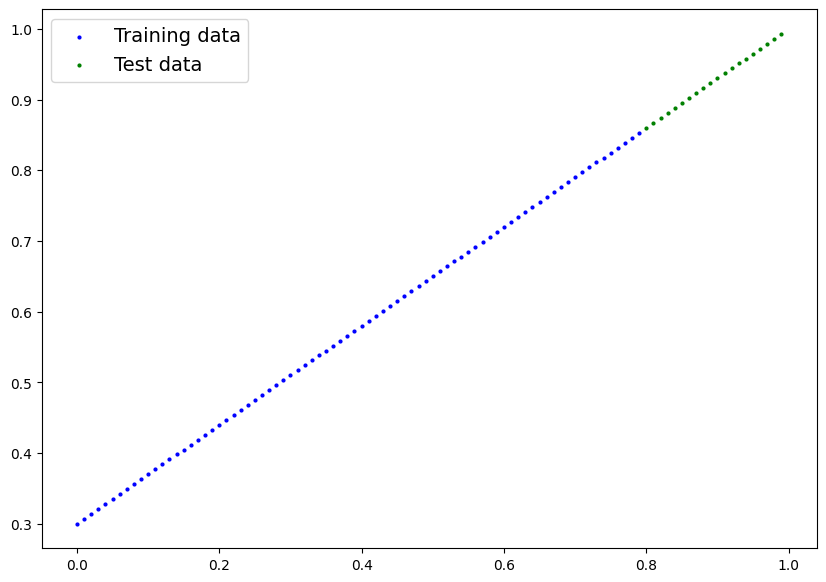

In [45]:
plot_predictions()

#Linear Regression model class


Topics include OOP

nn.module
- almost everything from PyTorch inherits from it
- it is the subclass that contains all the building blocks for neural networks


-> Initializing model parameters - could be different layers from torch.nn, single parameters, functions or hard coded values

-> requires auto_grad is True by default, gradients are tracked to be used with torch.autograd()

-> Any subclass of nn.Module needs to override **forward()** :  this defines the forward computation of model






# Forward(*input):

- defines the computation performed at every step

- in our case it is the linear regression function y = ax + b

Our model starts with random values - (weights and biases); look at training data and adjust the random values to better represent the ideal values (i.e. the ones we used to create our data)

How?

1) Gradient descent
2) Back propogation

In [46]:
class LinearRegressionModel(nn.Module): #Base class for all neural network modules
  def __init__(self):
    super().__init__()

    #Initializing model parameters -> creating random tensors
    self.weights = nn.Parameter(torch.randn(1, requires_grad=True)
    )
    self.bias = nn.Parameter(torch.randn(1, requires_grad=True)
    )

  #forward method to define the computation of the model
  # x is the input data
  def forward(self, x: torch.Tensor) -> torch.Tensor:
    return self.weights * x + self.bias #our linear regression function

#Pytorch model building essentials

- torch.nn - contains all of the buildings for computational graphs aka nn

- torch.nn.Module - The base class for all nn modules; if you subclass it you should override it

- nn.Parameter  - what parameters should our model try and learn, often a PyTorch layer from torch.nn set these for us

- torch.Optim - optimizers that will help with GD live here


#Parameter:

**value that the model sets itself**

In [47]:
#create a random seed so that we can get reproducibility, you need to reinitialize the seed before creating another tensor otherwise it doesn't carry over

torch.manual_seed(42)

model_0 = LinearRegressionModel()

list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [48]:
#named parameters

model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

#Torch.inference_mode()

To check our model's predictive power, we can check how well it predicts y_test and x_test. When we pass data through our model, it's going to run through it through the forward() method

In [49]:
with torch.inference_mode():
  y_preds = model_0(X_test)

y_preds

tensor([[0.3982],
        [0.4015],
        [0.4049],
        [0.4083],
        [0.4116],
        [0.4150],
        [0.4184],
        [0.4217],
        [0.4251],
        [0.4285],
        [0.4318],
        [0.4352],
        [0.4386],
        [0.4419],
        [0.4453],
        [0.4487],
        [0.4520],
        [0.4554],
        [0.4588],
        [0.4621]])

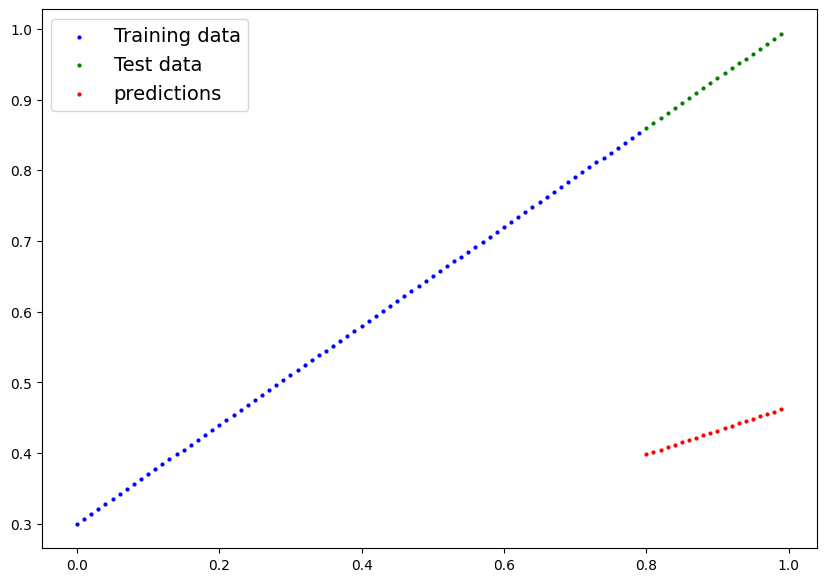

In [50]:
# Make sure you have fixed the forward method in LinearRegressionModel first!
# Then re-run the prediction block to update y_preds.
plot_predictions(predictions=y_preds.cpu().numpy() if hasattr(y_preds, 'cpu') else y_preds)

since the predictions are really off, we're going to need to know how poor our predictions are using a Loss Function.
- also called cost function/criterion
- goal is to always minimize the loss function

`nn` in torch hss a lot of loss function methods

- **Optimizer** takes into account the loss of a function and adjusts the model's parameters

In **PyTorch**:
- training loop:
  1) Loop through the data
  2) foward pass (involves going through our forward passes/propogation)
  3) calculate the loss (compare forward pass predictions to ground truth label)
  4) Optimizer zero grad
  5) Loss backward - move backward thorugh thr network to calculate the gradients of each of the parameters of our model with respect to the loss
  6) Optimizer step - use the optimizer to adjust the parameters and improve the loss  

- testing loop

- nn.L1loss : creates a criterion/loss fn that measure the MAE between each element in the input x and target y

- nn.MSELoss - measures Mean Squared Error (MSE)

etc. for different losses

 SGD: Stochastic gradient descent - random GD

In [51]:
#Setting up loss function
#we want to minimize the absolute distance between
#our prediction and the targets

loss_fn = nn.L1Loss()

#Setting up an Optimizer
optimizer = torch.optim.SGD(params = model_0.parameters(),
                            lr = 0.01) #learning rate

#lr hyperparam that defines how big/small the optimizer changes
#the parameters with each step



** parameters are set by the model, hyperparameters are set by the developer**

In [54]:
#an epoch is one loop through the data

epochs = 170

#1) loop through the data
for epoch in range(epochs):
  model_0.train() #sets all parameters that requires gradients = true

  #2) Forward pass
  y_pred = model_0(X_train)

  #3) Calculate the loss
  loss = loss_fn(y_pred, y_train)

  #4) optimizer
  optimizer.zero_grad()

  #5) back propogation
  loss.backward()

  #6) Set up the the optimizer - perform gradient descent
  optimizer.step()
  #by default how the optimizer changes will accumulate through the loop
  #that's why it's essential to reinitialize it to zero in the above step

  #Testing
  model_0.eval() #sets all parameters that requires gradients = false
  with torch.inference_mode(): #turns off gradient tracking and a coupl more things needed for training only
    #1. forward pass
    test_pred = model_0(X_test)

    #2. loss fn
    test_loss = loss_fn(test_pred, y_test)

    if epoch % 10 == 0:
      print(f"Epoch: {epoch} | Loss: {loss} | Test loss: {test_loss}")

  print(model_0.state_dict())
  print(f"Epoch: {epoch} | Loss: {loss}")

Epoch: 0 | Loss: 0.007127122487872839 | Test loss: 0.01589217223227024
OrderedDict({'weights': tensor([0.6663]), 'bias': tensor([0.3143])})
Epoch: 0 | Loss: 0.007127122487872839
OrderedDict({'weights': tensor([0.6679]), 'bias': tensor([0.3136])})
Epoch: 1 | Loss: 0.006784421857446432
OrderedDict({'weights': tensor([0.6696]), 'bias': tensor([0.3128])})
Epoch: 2 | Loss: 0.006441720761358738
OrderedDict({'weights': tensor([0.6713]), 'bias': tensor([0.3121])})
Epoch: 3 | Loss: 0.006099019665271044
OrderedDict({'weights': tensor([0.6730]), 'bias': tensor([0.3113])})
Epoch: 4 | Loss: 0.0057563139125704765
OrderedDict({'weights': tensor([0.6748]), 'bias': tensor([0.3108])})
Epoch: 5 | Loss: 0.005414118524640799
OrderedDict({'weights': tensor([0.6765]), 'bias': tensor([0.3101])})
Epoch: 6 | Loss: 0.005071887280791998
OrderedDict({'weights': tensor([0.6782]), 'bias': tensor([0.3093])})
Epoch: 7 | Loss: 0.0047291857190430164
OrderedDict({'weights': tensor([0.6799]), 'bias': tensor([0.3086])})
Ep

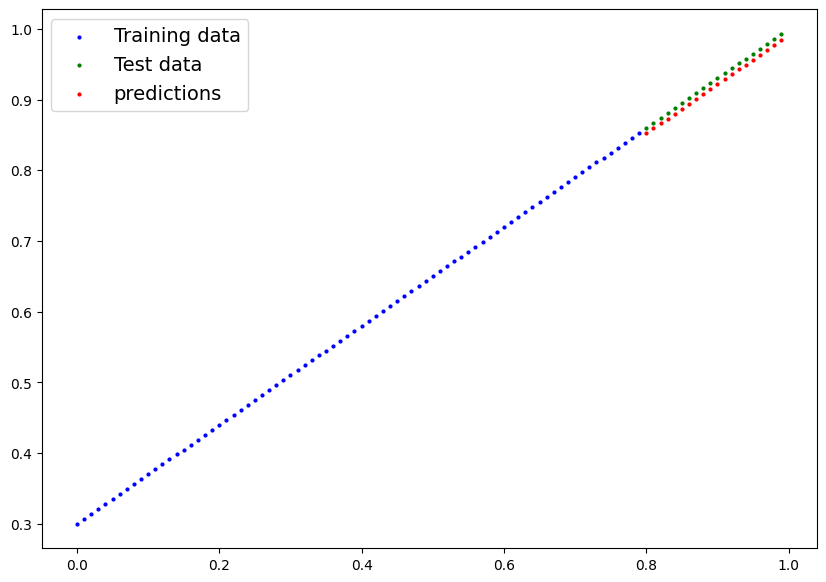

In [55]:
with torch.inference_mode():
  y_preds_new = model_0(X_test)

plot_predictions(predictions=y_preds_new)